In [ ]:
from sklearn.datasets import load_iris

data = load_iris()
X = data.data
y = data.target

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Split the Iris dataset into training and testing sets
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Standardize features (highly recommended for Neural Networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_iris)
X_test_scaled = scaler.transform(X_test_iris)

# Initialize and train the MLP Classifier with increased max_iter to ensure convergence
mlp_model = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42)
mlp_model.fit(X_train_scaled, y_train_iris)

# Make predictions
y_pred_iris = mlp_model.predict(X_test_scaled)

# Evaluate and print results
accuracy = accuracy_score(y_test_iris, y_pred_iris)
print(f"Neural Network Test Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test_iris, y_pred_iris, target_names=data.target_names))

Neural Network Test Accuracy: 0.9111

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



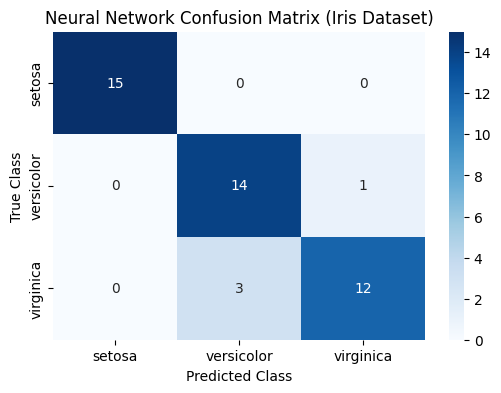

In [ ]:
# Plot Confusion Matrix
cm = confusion_matrix(y_test_iris, y_pred_iris)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, cmap='Blues', xticklabels=data.target_names, yticklabels=data.target_names)
plt.title('Neural Network Confusion Matrix (Iris Dataset)')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.show()

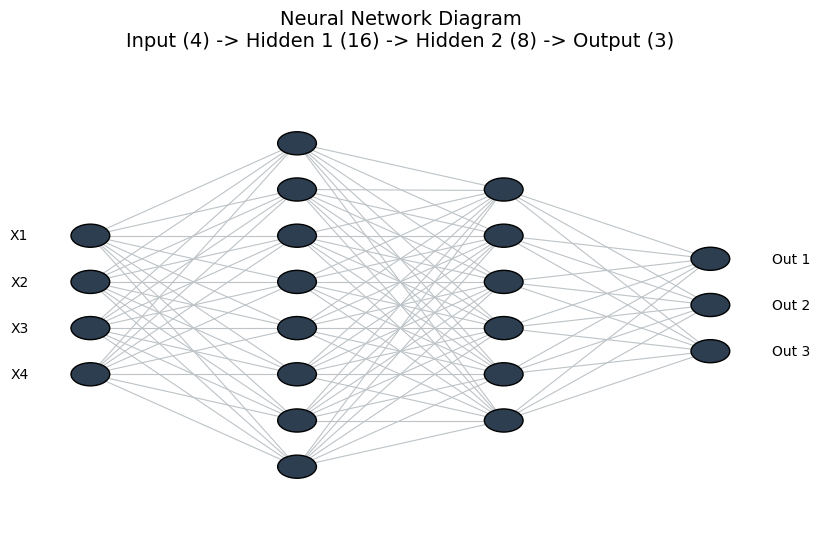

In [ ]:
import matplotlib.pyplot as plt

def draw_neural_network(ax, layer_sizes):
    '''
    Draws a simple neural network schematic diagram.
    '''
    left, right, bottom, top = 0.1, 0.9, 0.1, 0.9
    n_layers = len(layer_sizes)
    v_spacing = (top - bottom) / float(max(layer_sizes))
    h_spacing = (right - left) / float(n_layers - 1)

    # Nodes
    for n, layer_size in enumerate(layer_sizes):
        layer_top = v_spacing * (layer_size - 1) / 2. + (top + bottom) / 2.
        for m in range(layer_size):
            circle = plt.Circle((n * h_spacing + left, layer_top - m * v_spacing),
                                v_spacing / 4., color='#2c3e50', ec='k', zorder=4)
            ax.add_artist(circle)

            # Node labels
            if n == 0:
                ax.text(n * h_spacing + left - 0.08, layer_top - m * v_spacing, f'X{m+1}', ha='right', va='center')
            elif n == n_layers - 1:
                ax.text(n * h_spacing + left + 0.08, layer_top - m * v_spacing, f'Out {m+1}', ha='left', va='center')

    # Edges
    for n, (layer_size_a, layer_size_b) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:])):
        layer_top_a = v_spacing * (layer_size_a - 1) / 2. + (top + bottom) / 2.
        layer_top_b = v_spacing * (layer_size_b - 1) / 2. + (top + bottom) / 2.
        for m in range(layer_size_a):
            for o in range(layer_size_b):
                line = plt.Line2D([n * h_spacing + left, (n + 1) * h_spacing + left],
                                  [layer_top_a - m * v_spacing, layer_top_b - o * v_spacing],
                                  color='#bdc3c7', linewidth=0.8, zorder=1)
                ax.add_artist(line)

fig, ax = plt.subplots(figsize=(10, 6))
ax.axis('off')
# To make a clean diagram, we show a scaled-down representation of the layers (4 inputs, 8 hidden, 6 hidden, 3 outputs)
# so the visual lines do not look excessively cluttered, while representing the (4, 16, 8, 3) network structure.
draw_neural_network(ax, [4, 8, 6, 3])

plt.title('Neural Network Diagram\nInput (4) -> Hidden 1 (16) -> Hidden 2 (8) -> Output (3)', fontsize=14, pad=20)
plt.show()